# 02 · Análisis exploratorio (EDA) y control de duplicados
**Entrega 1 · cronograma días 3–5.** No necesita GPU. Requiere haber ejecutado el notebook 01.

Preguntas que responde: ¿cuántas fotos hay de cada clase?, ¿cómo se ven?, ¿hay fotos repetidas entre
entrenamiento y prueba (fuga de información)?

In [1]:
# PREPARACIÓN (igual en todos los notebooks): conecta Drive, entra a la carpeta del proyecto y deja listos los datos.
from google.colab import drive
drive.mount('/content/drive')

PROYECTO = '/content/drive/MyDrive/yuca-comparacion'   # carpeta del proyecto dentro de su Google Drive

import os, sys
os.chdir(PROYECTO)
sys.path.insert(0, PROYECTO)

from src.datos import descargar_dataset
# El .zip se guarda una sola vez en Drive; las fotos se descomprimen en el disco de Colab (más rápido).
RAIZ = str(descargar_dataset(destino='/content/datos', carpeta_zip=PROYECTO + '/data'))
os.environ['YUCA_DATOS'] = RAIZ
print('Proyecto:', os.getcwd())
print('Datos   :', RAIZ)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[ok] El dataset ya está descomprimido en: /content/datos/cassavaleafdata
Proyecto: /content/drive/MyDrive/yuca-comparacion
Datos   : /content/datos/cassavaleafdata


In [2]:
import pandas as pd
from IPython.display import Image as Mostrar, display
from src import eda
inventario = pd.read_csv('resultados/inventario.csv')
len(inventario)

9430

## 1. Distribución de clases
Si una clase tiene muchas más fotos que otra, hay **desbalance**: un modelo puede acertar mucho solo por preferir la clase grande.

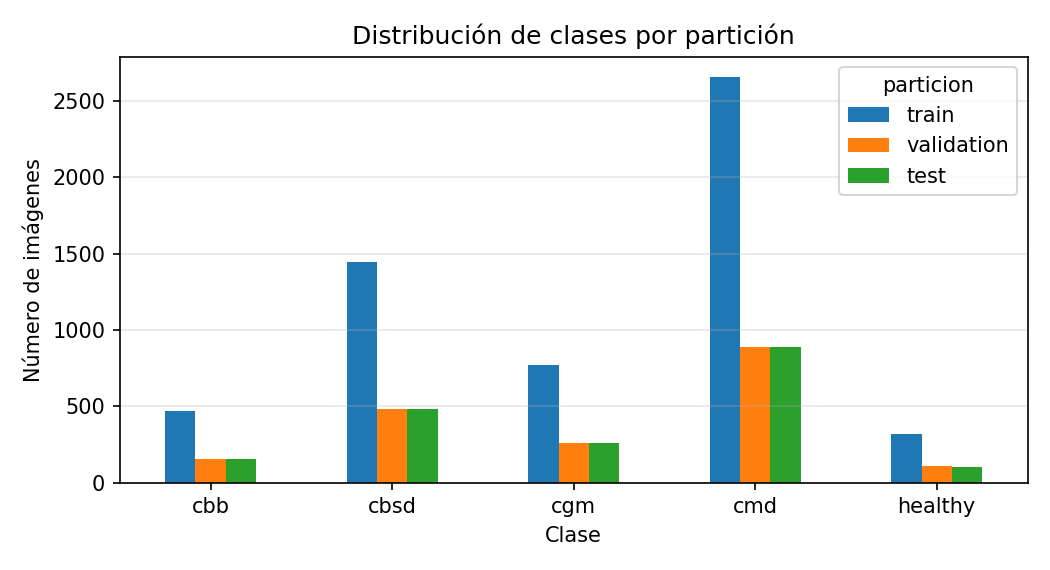

particion,train,validation,test
clase,,,
cbb,466,156,155
cbsd,1443,482,481
cgm,773,258,258
cmd,2658,887,886
healthy,316,106,105


In [3]:
tabla = eda.grafica_distribucion(inventario)
display(Mostrar('resultados/eda/distribucion_clases.png'))
tabla

## 2. Tamaño de las imágenes

In [4]:
eda.resumen_resoluciones(inventario)

,ancho,alto,bytes
count,9430.0,9430.0,9430.0
mean,611.6,572.0,143599.7
std,140.0,109.3,69054.1
min,420.0,347.0,31236.0
25%,500.0,500.0,82224.8
50%,543.0,500.0,135494.5
75%,666.0,666.0,190164.2
max,1622.0,1240.0,481881.0


## 3. Ejemplos de cada clase
Miren las fotos con calma: fondos, iluminación, si la hoja ocupa toda la imagen, si hay manos o suelo. Anoten lo que observen.

In [5]:
display(Mostrar(str(eda.mosaico_ejemplos(inventario, RAIZ, por_clase=5, semilla=0))))

Output hidden; open in https://colab.research.google.com to view.

## 4. Brillo promedio por clase
Si una clase suele estar más clara u oscura, el modelo podría usar el brillo como **atajo** en vez de mirar la lesión.

In [6]:
eda.brillo_medio(inventario, RAIZ)

,mean,std,count
clase,,,
cbb,114.5,17.1,60
cbsd,117.8,17.8,60
cgm,124.0,15.7,60
cmd,114.8,17.4,60
healthy,116.1,13.3,60


## 5. Duplicados exactos
Archivos idénticos byte a byte. Los que tienen `entre_particiones = True` son fuga de información.

In [7]:
exactos = eda.duplicados_exactos(inventario)
exactos.to_csv('resultados/eda/duplicados_exactos.csv', index=False)
print('Archivos repetidos:', len(exactos), '| grupos:', exactos['md5'].nunique(),
      '| archivos en grupos que cruzan particiones:', int(exactos['entre_particiones'].sum()))
exactos.head(20)

Archivos repetidos: 68 | grupos: 26 | archivos en grupos que cruzan particiones: 45


,md5,particion,clase,ruta,entre_particiones
465,206e79f52dbb5506358c47890dba99ef,train,cbb,train/cbb/train-cbb-99.jpg,False
1908,206e79f52dbb5506358c47890dba99ef,train,cbsd,train/cbsd/train-cbsd-999.jpg,False
2352,206e79f52dbb5506358c47890dba99ef,train,cgm,train/cgm/train-cgm-498.jpg,False
645,229c20a16bfb13dc1b413c50c4441c8b,train,cbsd,train/cbsd/train-cbsd-1159.jpg,True
6535,229c20a16bfb13dc1b413c50c4441c8b,validation,cgm,validation/cgm/validation-cgm-84.jpg,True
3653,2bcf7925245747c33a5ddfc53c6bdc89,train,cmd,train/cmd/train-cmd-1872.jpg,False
3986,2bcf7925245747c33a5ddfc53c6bdc89,train,cmd,train/cmd/train-cmd-2171.jpg,False
8032,3d83cddb63d8625c350029c2eb221352,test,cbsd,test/cbsd/test-cbsd-398.jpg,True
8188,3d83cddb63d8625c350029c2eb221352,test,cgm,test/cgm/test-cgm-104.jpg,True
139,3d83cddb63d8625c350029c2eb221352,train,cbb,train/cbb/train-cbb-223.jpg,True


## 6. Casi duplicados
Fotos visualmente casi iguales aunque el archivo sea distinto. Son **candidatos**: hay que mirarlos. Tarda unos minutos.

In [8]:
casi = eda.casi_duplicados(inventario, RAIZ, distancia_max=2)
casi.to_csv('resultados/eda/casi_duplicados.csv', index=False)
print('Pares candidatos:', len(casi), '| entre particiones:', int(casi['entre_particiones'].sum()))
casi.sort_values('distancia').head(20)

Pares candidatos: 29 | entre particiones: 19


,ruta_a,ruta_b,particion_a,particion_b,clase_a,clase_b,distancia,entre_particiones
11,train/cbsd/train-cbsd-55.jpg,validation/healthy/validation-healthy-82.jpg,train,validation,cbsd,healthy,0,True
23,train/healthy/train-healthy-292.jpg,train/healthy/train-healthy-50.jpg,train,train,healthy,healthy,0,False
25,validation/cbsd/validation-cbsd-117.jpg,test/cbsd/test-cbsd-36.jpg,validation,test,cbsd,cbsd,0,True
3,train/cbsd/train-cbsd-127.jpg,validation/cbsd/validation-cbsd-473.jpg,train,validation,cbsd,cbsd,1,True
15,train/cgm/train-cgm-332.jpg,validation/cgm/validation-cgm-73.jpg,train,validation,cgm,cgm,1,True
9,train/cbsd/train-cbsd-281.jpg,test/cbsd/test-cbsd-36.jpg,train,test,cbsd,cbsd,1,True
7,train/cbsd/train-cbsd-146.jpg,test/cbsd/test-cbsd-479.jpg,train,test,cbsd,cbsd,1,True
2,train/cbsd/train-cbsd-1068.jpg,train/cbsd/train-cbsd-530.jpg,train,train,cbsd,cbsd,1,False
28,test/cbsd/test-cbsd-260.jpg,test/cbsd/test-cbsd-303.jpg,test,test,cbsd,cbsd,1,False
26,validation/cbsd/validation-cbsd-141.jpg,validation/cbsd/validation-cbsd-227.jpg,validation,validation,cbsd,cbsd,1,False


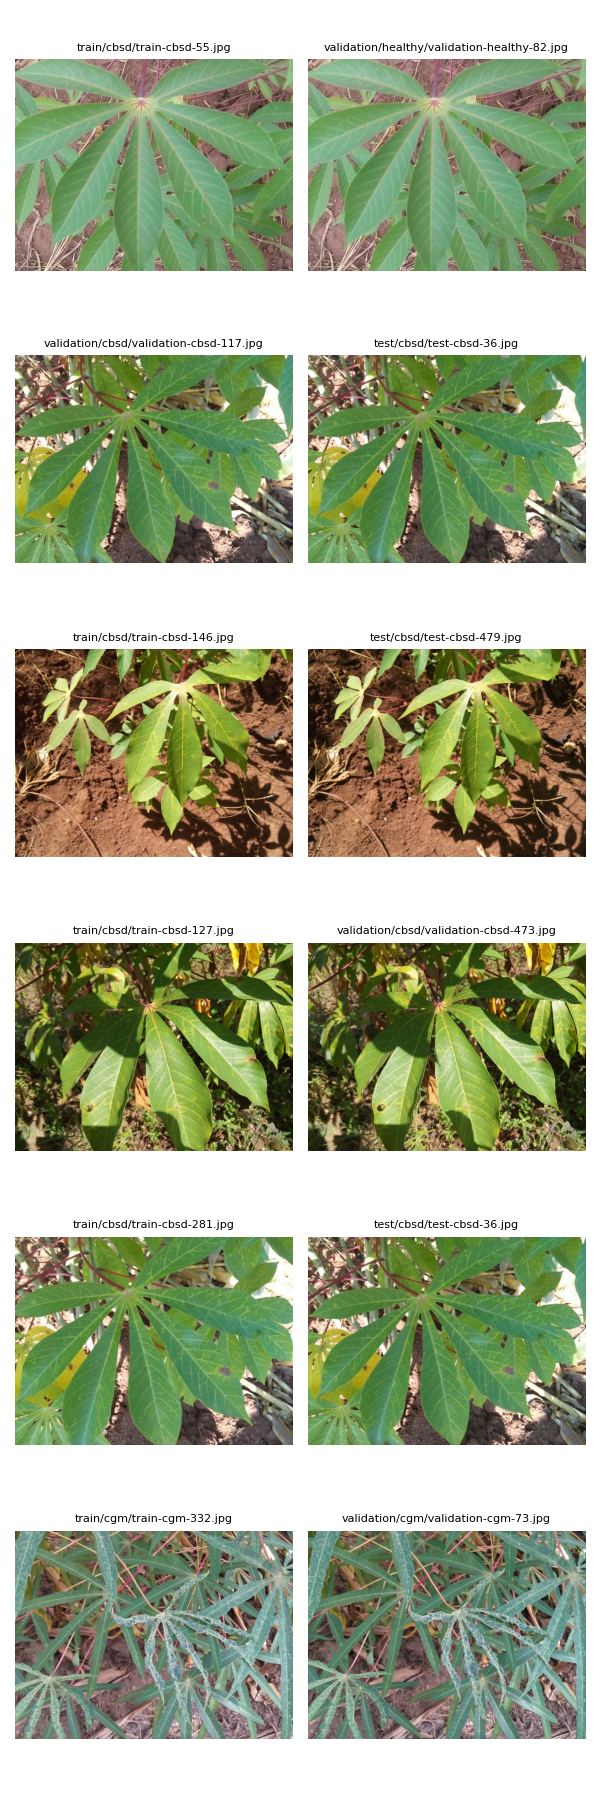

In [9]:
ruta = eda.mostrar_pares(casi[casi['entre_particiones']].sort_values('distancia'), RAIZ, n=6)
display(Mostrar(str(ruta))) if ruta else print('No hay pares entre particiones para mostrar')

## 7. Decisión del equipo: qué excluir
El conjunto de **prueba nunca se modifica**. La función retira de entrenamiento/validación las imágenes idénticas a
otra de una partición con más prioridad (prueba > validación > entrenamiento).

- `incluir_casi=False`: solo se retiran duplicados exactos.
- `incluir_casi=True`: también los casi duplicados entre particiones (después de revisarlos arriba).

Registren la decisión y el motivo en `docs/02_protocolo.md` y en la bitácora.

In [10]:
INCLUIR_CASI = True             # decisión del equipo (2026-11-15): retirar casi duplicados entre particiones
RETIRAR_CONFLICTIVAS = True     # decisión del equipo (2026-11-15): retirar fotos con etiquetas contradictorias

excluidos = eda.generar_exclusiones(inventario, casi, incluir_casi=INCLUIR_CASI, retirar_conflictivas=RETIRAR_CONFLICTIVAS)
excluidos.to_csv('resultados/excluidos.csv', index=False)
print('Imágenes que se retiran:', len(excluidos))
print(excluidos['motivo'].str.split(' ').str[0].value_counts())
excluidos.head(20)

Imágenes que se retiran: 68
motivo
misma       42
casi        18
idéntica     8
Name: count, dtype: int64


,ruta,motivo
0,train/cbb/train-cbb-129.jpg,misma foto con etiquetas distintas (cbb/cbsd/cgm)
1,train/cbb/train-cbb-140.jpg,misma foto con etiquetas distintas (cbb/cbsd/cgm)
2,train/cbb/train-cbb-145.jpg,misma foto con etiquetas distintas (cbb/cbsd)
3,train/cbb/train-cbb-223.jpg,misma foto con etiquetas distintas (cbb/cbsd/cgm)
4,train/cbb/train-cbb-224.jpg,misma foto con etiquetas distintas (cbb/cbsd/cgm)
5,train/cbb/train-cbb-237.jpg,misma foto con etiquetas distintas (cbb/cbsd/cgm)
6,train/cbb/train-cbb-288.jpg,misma foto con etiquetas distintas (cbb/cbsd/cgm)
7,train/cbb/train-cbb-324.jpg,misma foto con etiquetas distintas (cbb/cbsd/cgm)
8,train/cbb/train-cbb-412.jpg,misma foto con etiquetas distintas (cbb/cbsd/cgm)
9,train/cbb/train-cbb-427.jpg,misma foto con etiquetas distintas (cbb/cbsd/cgm)


In [11]:
# Comprobación: cómo quedan las particiones que usarán TODOS los experimentos
from src.dataset import cargar_particiones
partes = cargar_particiones()
{nombre: len(tabla) for nombre, tabla in partes.items()}

{'train': 5600, 'validation': 1877, 'test': 1885}